<a href="https://colab.research.google.com/github/nurilhuda05/PCVK_Ganjil_2026/blob/main/P7_17_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CELL IDENTITAS**

In [51]:
NAMA = 'Muhammad Nuril Huda'
NIM = '244107020004'
print(NAMA, NIM)

Muhammad Nuril Huda 244107020004


# **D. TUGAS PRAKTIKUM**

## **D1. Tugas Individu**

### **1. Persiapan Google Colab**

In [52]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2. Import Library**

In [53]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

### **3. Membuat Global Treshhold Secara Manual**

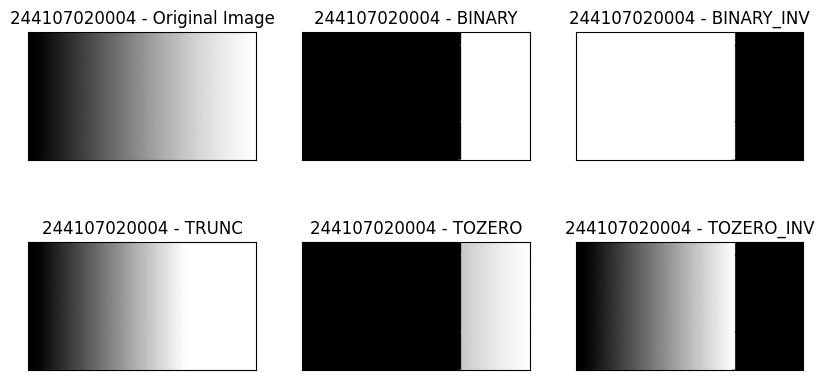

In [54]:
filename = ('/content/drive/MyDrive/Semester 5/PCVK/images/gradient.jpg')
img = cv.imread(filename,0)

thresh = 200
maxval = 255

binary = np.where(img > thresh, maxval, 0)

binary_inv = np.where(img > thresh, 0, maxval)

trunc = np.where(img > thresh, thresh, img)

tozero = np.where(img > thresh, img, 0)

tozero_inv = np.where(img > thresh, 0, img)

plt.figure(figsize = (10,5))
plt.subplot(2,3,1)
plt.imshow(img,'gray')
plt.title(NIM+' - Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(2,3,2)
plt.imshow(binary,'gray')
plt.title(NIM+' - BINARY')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 3, 3)
plt.imshow(binary_inv, 'gray')
plt.title(NIM+' - BINARY_INV')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 3, 4)
plt.imshow(trunc, 'gray')
plt.title(NIM+' - TRUNC')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 3, 5)
plt.imshow(tozero, 'gray')
plt.title(NIM+' - TOZERO')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 3, 6)
plt.imshow(tozero_inv, 'gray')
plt.title(NIM+' - TOZERO_INV')
plt.xticks([])
plt.yticks([])

plt.show()

### **4. Adaptive Threshold**

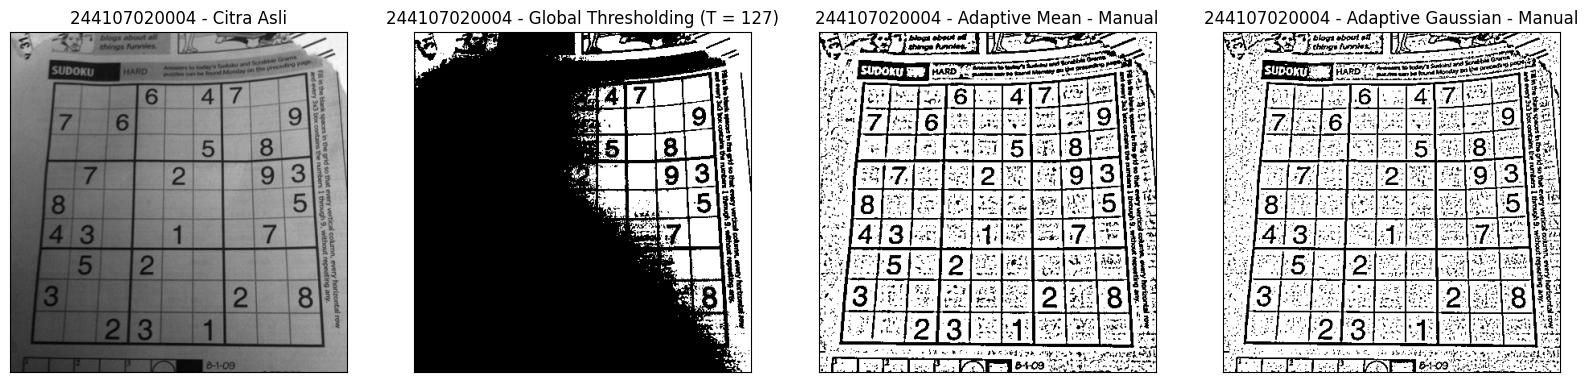

In [55]:
filename = ('/content/drive/MyDrive/Semester 5/PCVK/images/sudoku-original.jpg')
img = cv.imread(filename, 0)

thresh = 127
maxval = 255
window = 11
C = 2
sigma = 2

pad = window // 2
padded = np.pad(img, pad, mode='reflect')

# Global Thresholding
global_threshold = np.where(img > thresh, maxval, 0)

# Adaptive Mean Thresholding - Manual
adaptive_mean = np.zeros_like(img)

for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        area = padded[i:i+window, j:j+window]

        mean = np.mean(area)
        threshold = mean - C

        if img[i, j] > threshold:
            adaptive_mean[i, j] = 255
        else:
            adaptive_mean[i, j] = 0

# Adaptive Gaussian Thresholding - Manual
x = np.arange(-pad, pad + 1)
y = np.arange(-pad, pad + 1)

X, Y = np.meshgrid(x, y)

kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
kernel = kernel / np.sum(kernel)

adaptive_gaussian = np.zeros_like(img)

for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        area = padded[i:i+window, j:j+window]

        weighted_mean = np.sum(area * kernel)
        threshold = weighted_mean - C

        if img[i, j] > threshold:
            adaptive_gaussian[i, j] = 255
        else:
            adaptive_gaussian[i, j] = 0


# Menampilkan
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(img, 'gray')
plt.title(NIM+' - Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 2)
plt.imshow(global_threshold, 'gray')
plt.title(NIM+' - Global Thresholding (T = 127)')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 3)
plt.imshow(adaptive_mean, 'gray')
plt.title(NIM+' - Adaptive Mean - Manual')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 4)
plt.imshow(adaptive_gaussian, 'gray')
plt.title(NIM+' - Adaptive Gaussian - Manual')
plt.xticks([])
plt.yticks([])

plt.show()

### **5A. Implementasi dan Perbandingan Otsu Thresholding Manual dengan Library pada Citra Lena**

Threshold Otsu Manual  : 125
Threshold Otsu Library : 124.0


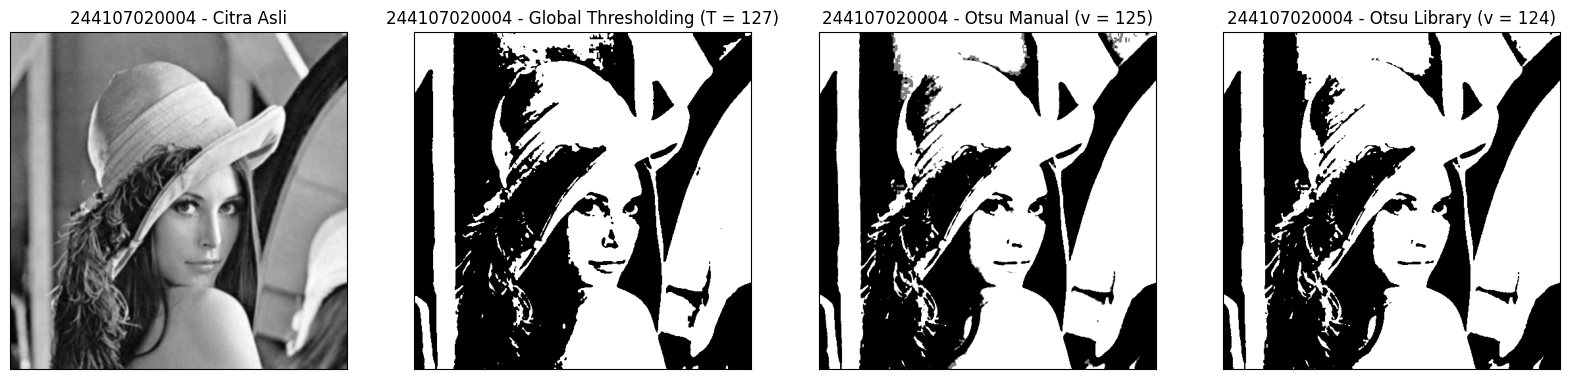

In [62]:
filename = ('/content/drive/MyDrive/Semester 5/PCVK/images/lena_gs_lc2.jpg')
img = cv.imread(filename, 0)

blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

# Otsu Thresholding - Manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number

    his, bins = np.histogram(gray, np.arange(0, 257))

    final_thresh = -1
    final_value = -1

    intensity_arr = np.arange(256)
    for t in bins[1:-1]:

        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        if Wb == 0 or Wf == 0:
            continue

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()

    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0

    return final_img, final_thresh

# Memanggil Otsu Manual
otsu_biner, otsu_thresh = otsu(blur)

# Otsu Thresholding - Library
ret, otsu_library = cv.threshold(blur,0,255,cv.THRESH_BINARY + cv.THRESH_OTSU)

# Global Thresholding
global_threshold = np.where(blur > thresh, 255, 0)


print("Threshold Otsu Manual  :", otsu_thresh)
print("Threshold Otsu Library :", ret)

# Menampilkan Hasil
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(blur, 'gray')
plt.title(NIM+' - Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 2)
plt.imshow(global_threshold, 'gray')
plt.title(NIM+' - Global Thresholding (T = 127)')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 3)
plt.imshow(otsu_biner, 'gray')
plt.title(NIM+" - Otsu Manual (v = " + str(otsu_thresh) + ")")
plt.xticks([])
plt.yticks([])

plt.subplot(1, 4, 4)
plt.imshow(otsu_library, 'gray')
plt.title(NIM+" - Otsu Library (v = " + str(int(ret)) + ")")
plt.xticks([])
plt.yticks([])


plt.show()

**Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?**


Hasil Binary Thresholding dapat menjadi seluruhnya hitam apabila nilai threshold yang digunakan lebih tinggi daripada sebagian besar nilai intensitas piksel pada citra. Pada Binary Thresholding, piksel yang memiliki nilai lebih besar dari threshold akan diubah menjadi 255 atau putih, sedangkan piksel yang nilainya lebih kecil atau sama dengan threshold akan diubah menjadi 0 atau hitam. Oleh karena itu, apabila histogram menunjukkan bahwa sebagian besar nilai piksel berada di bawah Thresh = 127, maka sebagian besar piksel akan berubah menjadi hitam dan gambar dapat terlihat sangat gelap atau bahkan seluruhnya hitam.
Berdasarkan hasil praktikum yang diperoleh, Otsu secara manual menghasilkan nilai threshold 125, sedangkan Otsu menggunakan library menghasilkan 124. Kedua nilai tersebut menghasilkan gambar Lena yang masih terlihat dengan jelas. Hal ini menunjukkan bahwa threshold sekitar 124–125 dapat digunakan untuk memisahkan bagian gelap dan terang pada citra yang digunakan dalam praktikum. Perbedaan nilai 125 dan 124 hanya satu tingkat dan hasil gambar keduanya juga terlihat hampir sama.

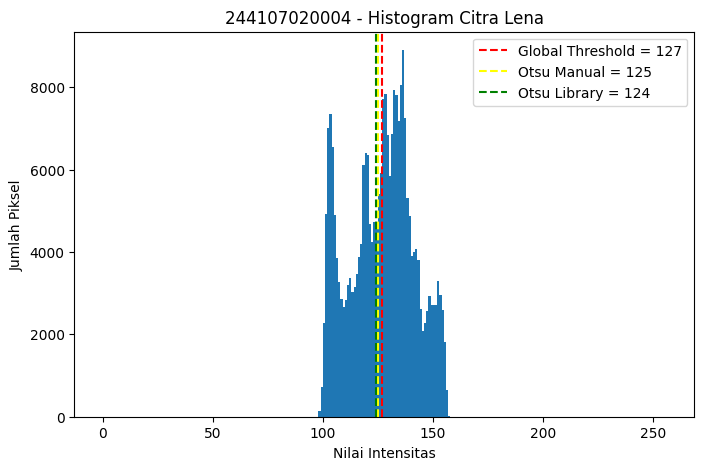

In [63]:
plt.figure(figsize=(8, 5))

plt.hist(blur.ravel(), bins=256, range=[0, 256])

plt.axvline(127, color='red', linestyle='--', label='Global Threshold = 127')
plt.axvline(125, color='yellow', linestyle='--', label='Otsu Manual = 125')
plt.axvline(124, color='green', linestyle='--', label='Otsu Library = 124')

plt.title(NIM+' - Histogram Citra Lena')
plt.xlabel('Nilai Intensitas')
plt.ylabel('Jumlah Piksel')
plt.legend()

plt.show()

Histogram menunjukkan bahwa nilai intensitas piksel citra Lena sebagian besar berada pada rentang 100–160. Garis threshold 127, 125, dan 124 berada di dalam distribusi tersebut, sehingga dapat membagi piksel menjadi bagian gelap dan terang. Hasil Otsu Manual (125) dan Otsu Library (124) juga hampir sama karena perbedaannya hanya 1 tingkat.

### **5B. Perbandingan Global Thresholding dan Otsu Thresholding pada Citra KTP**

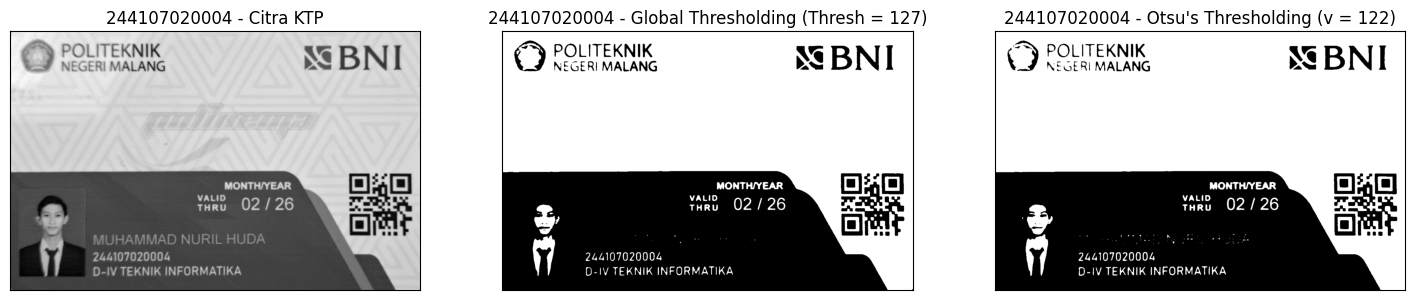

In [65]:
filename = ('/content/drive/MyDrive/Semester 5/PCVK/images/244107020004/KTM1d.jpg')
img = cv.imread(filename, 0)

blur = cv.GaussianBlur(img, (5, 5), 0)

thresh = 127

# Global Tresholding
global_threshold = np.where(blur > thresh, 255, 0)

# Otsu Thresholding
otsu_biner, otsu_thresh = otsu(blur)

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.imshow(blur, 'gray')
plt.title(NIM+' - Citra KTP')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 3, 2)
plt.imshow(global_threshold, 'gray')
plt.title(NIM+' - Global Thresholding (Thresh = 127)')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 3, 3)
plt.imshow(otsu_biner, 'gray')
plt.title(NIM+" - Otsu's Thresholding (v = " + str(otsu_thresh) + ")")
plt.xticks([])
plt.yticks([])
plt.show()
plt.show()

### **6A. Segmentasi Berbasis Region**

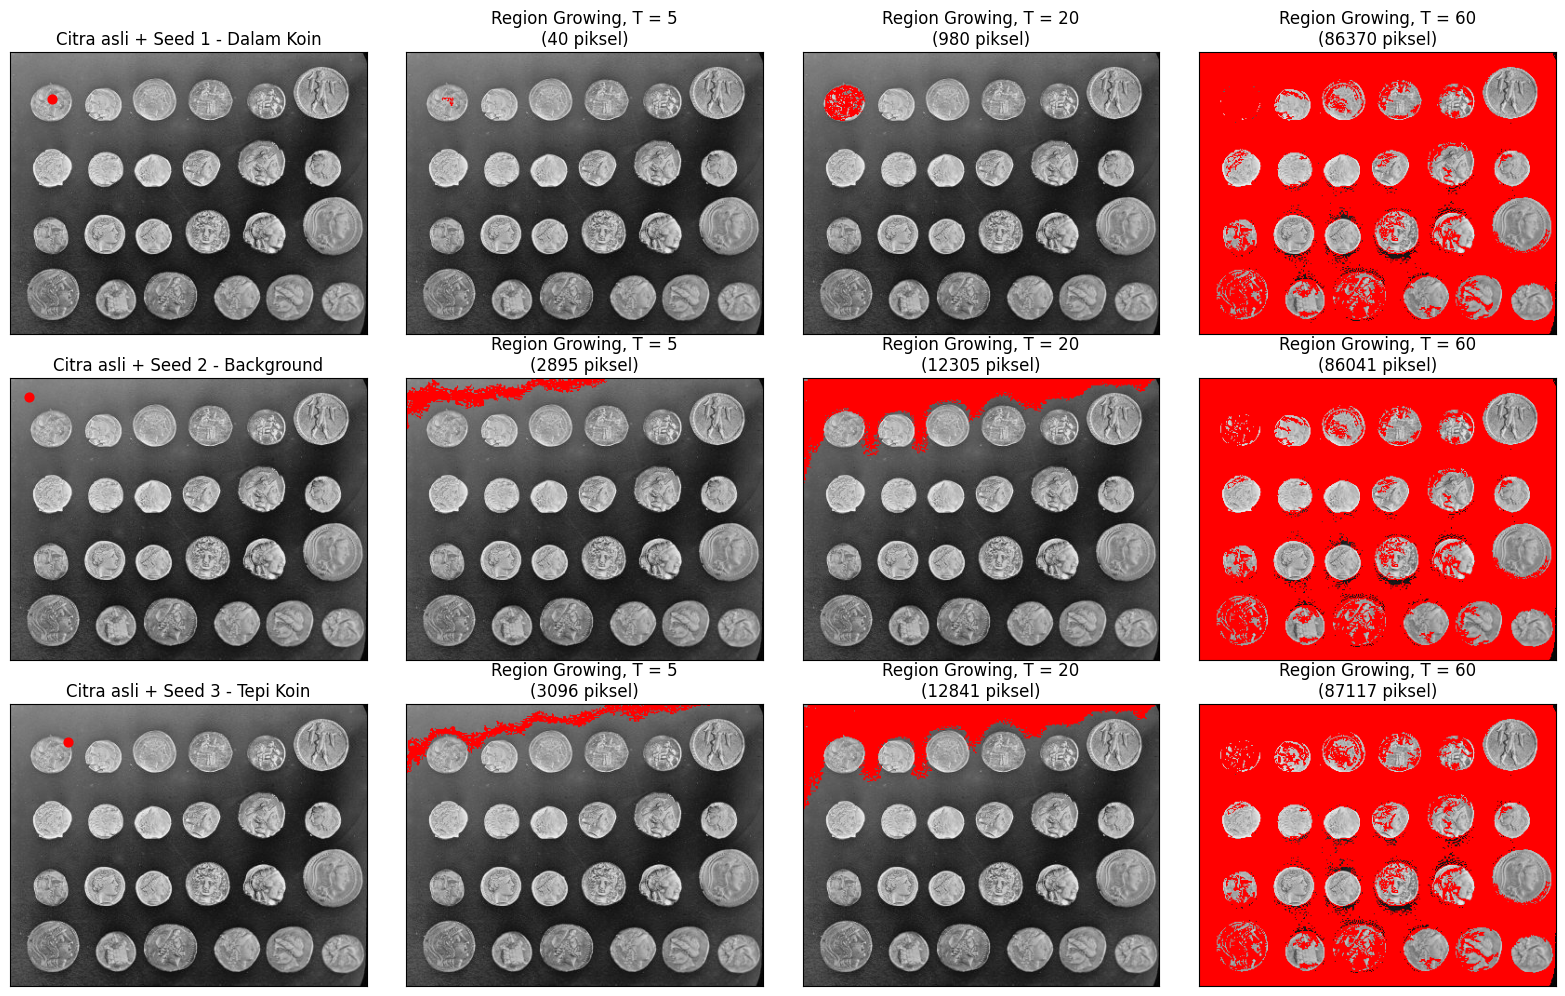

In [59]:
# Citra coins
img = data.coins()

# 3 seed
seed_dalam = (50, 45)    # Dalam koin
seed_latar = (20, 20)    # Background
seed_tepi = (40, 62)     # Tepi koin

# Fungsi Region Growing
def region_growing(img, seed, T):
    mask = np.zeros_like(img, dtype=np.uint8)

    queue = deque([seed])
    mask[seed] = 1

    mean_region = float(img[seed])
    jumlah = 1

    # 8 connectivity
    neighbors = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, -1),           (0, 1),
        (1, -1),  (1, 0),  (1, 1)
    ]

    while queue:
        r, c = queue.popleft()

        for dr, dc in neighbors:
            nr = r + dr
            nc = c + dc

            if 0 <= nr < img.shape[0] and 0 <= nc < img.shape[1]:

                if mask[nr, nc] == 0:

                    if abs(float(img[nr, nc]) - mean_region) < T:

                        mask[nr, nc] = 1
                        queue.append((nr, nc))

                        mean_region = (
                            (mean_region * jumlah) +
                            float(img[nr, nc])
                        ) / (jumlah + 1)

                        jumlah += 1

    return mask, jumlah


# Seed yang digunakan
seeds = [
    ('Seed 1 - Dalam Koin', seed_dalam),
    ('Seed 2 - Background', seed_latar),
    ('Seed 3 - Tepi Koin', seed_tepi)
]

# Nilai T
thresholds = [5, 20, 60]


plt.figure(figsize=(16, 10))

for i, (nama_seed, seed) in enumerate(seeds):

    # Citra asli + seed
    plt.subplot(3, 4, i * 4 + 1)

    plt.imshow(img, cmap='gray')
    plt.scatter(seed[1], seed[0], c='red', s=40)

    plt.title(f'Citra asli + {nama_seed}')
    plt.xticks([])
    plt.yticks([])

    # Region Growing T = 5, 20, 60
    for j, T in enumerate(thresholds):

        hasil, jumlah_piksel = region_growing(img, seed, T)

        # Membuat citra RGB dari citra grayscale
        hasil_overlay = cv.cvtColor(img, cv.COLOR_GRAY2RGB)

        # Memberikan warna merah pada region hasil
        hasil_overlay[hasil == 1] = [255, 0, 0]

        plt.subplot(3, 4, i * 4 + j + 2)

        plt.imshow(hasil_overlay)

        plt.title(
            f'Region Growing, T = {T}\n'
            f'({jumlah_piksel} piksel)'
        )

        plt.xticks([])
        plt.yticks([])

plt.tight_layout()
plt.show()

### **6B. Segmentasi Berbasis Region dengan Flood**

Seed (baris, kolom): (36, 43) | intensitas: 159.000000


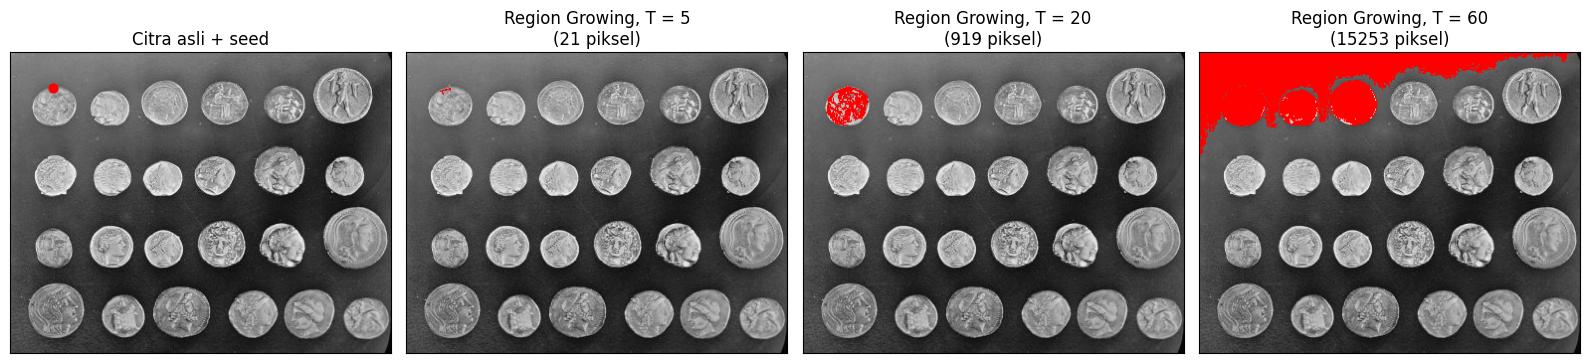

In [60]:
# Citra coins
gray = data.coins()

# Seed
seed = (36, 43)

# Nilai toleransi
tolerances = [5, 20, 60]

# Menampilkan informasi seed
print(f"Seed (baris, kolom): {seed} | intensitas: {gray[seed]:.6f}")

plt.figure(figsize=(16, 4))

# Citra asli + seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.scatter(seed[1], seed[0], c='red', s=40)
plt.title('Citra asli + seed')
plt.xticks([])
plt.yticks([])


# Flood untuk setiap tolerance
for i, T in enumerate(tolerances):

    region = flood(
        gray,
        seed_point=seed,
        tolerance=T,
        connectivity=1
    )

    # Menghitung jumlah piksel region
    jumlah_piksel = np.sum(region)

    # Membuat citra RGB
    hasil = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)

    # Memberikan warna merah pada region
    hasil[region] = [255, 0, 0]

    plt.subplot(1, 4, i + 2)

    plt.imshow(hasil)

    plt.title(
        f'Region Growing, T = {T}\n'
        f'({jumlah_piksel} piksel)'
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

### **7. Segmentasi Warna Biru pada Citra KTP Menggunakan K-Means dan HSV**

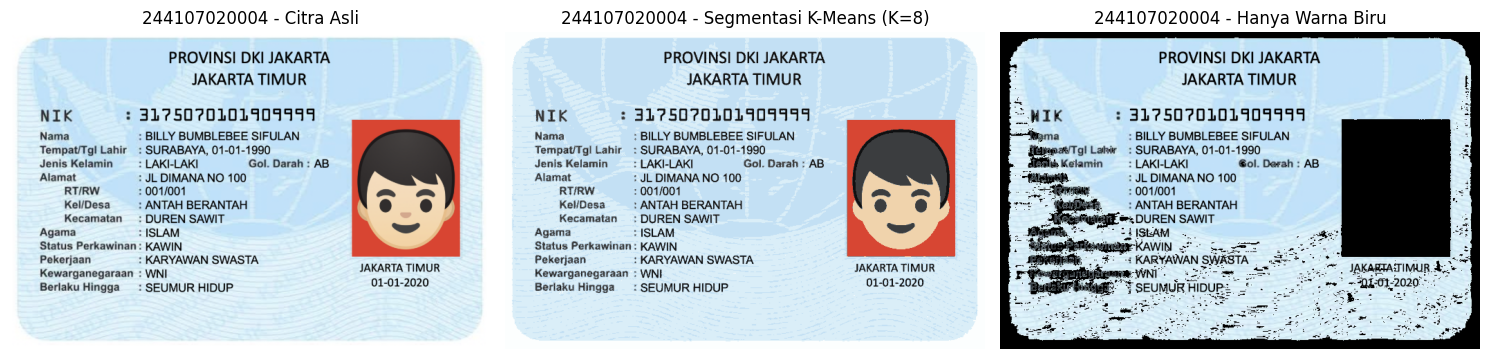

In [66]:
filename = '/content/drive/MyDrive/Semester 5/PCVK/images/ktp_fulan.jpg'
img = cv.imread(filename)
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# K-MEANS

# Mengubah citra menjadi array 2D
pixel = img_rgb.reshape((-1, 3))
pixel = np.float32(pixel)

# Jumlah cluster
K = 8

# Menjalankan K-Means
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER,100,0.2)

_, labels, centers = cv.kmeans(
    pixel,
    K,
    None,
    criteria,
    10,
    cv.KMEANS_PP_CENTERS
)

# Mengubah centroid menjadi uint8
centers = np.uint8(centers)

# Membentuk kembali citra hasil K-Means
hasil_kmeans = centers[labels.flatten()]
hasil_kmeans = hasil_kmeans.reshape(img_rgb.shape)


# SEGMENTASI WARNA BIRU

# Mengubah BGR menjadi HSV
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# Memisahkan channel HSV
H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

# Memilih piksel yang termasuk warna biru
kelompok_biru = np.where(
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

# Membuat hasil hanya warna biru
hasil_biru = np.zeros_like(img)
hasil_biru[kelompok_biru] = img[kelompok_biru]



plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title(NIM+' - Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hasil_kmeans)
plt.title(NIM+' - Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(hasil_biru, cv.COLOR_BGR2RGB))
plt.title(NIM+' - Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()